# Øvingsforelesning 10 - TDT4110

Øving 8: Plotting og sammensatte programmer

### Oppgave 1

Du får en dictionary med personer som nøkkel og en dictionary per person med filmanmeldelser som verdi. Eksempelvis:
```python
ratings = {
    "alice": {"Inception": 9, "Interstellar": 10, "Cars 2": 8, "The Dark Knight": 10},
    "bob": {"Inception": 7, "Tenet": 8, "The Dark Knight": 10, "Cars 2": 9},
    "carol": {"Inception": 10, "Interstellar": 9},
    "dave": {"Tenet": 6, "Interstellar": 9, "Cars 2": 7},
}
```
Lag en funksjon `analyze_ratings()` som tar inn dictionarien som argument og returner en ny dictionary med film som nøkkel og gjennomsnitt anmeldelsen for den filmen som verdi:
```python
>>> print(analyze_ratings(ratings))
# {'Inception': 8.67, 'Interstellar': 9.33, 'Cars 2': 8.0, 'The Dark Knight': 10.0, 'Tenet': 7.0}
```

In [34]:
def analyze_ratings(ratings):
  average_ratings = {}
  number_of_ratings = {}

  for personal_ratings in ratings.values():
    for movie, rating in personal_ratings.items():
      if movie not in average_ratings:
        average_ratings[movie] = rating 
        number_of_ratings[movie] = 1
      else:
        average_ratings[movie] += rating 
        number_of_ratings[movie] += 1

  for movie in average_ratings.keys():
    average_ratings[movie] = round(average_ratings[movie] / number_of_ratings[movie], 2)

  return average_ratings 

In [35]:
# Test kode her
ratings = {
    "alice": {"Inception": 9, "Interstellar": 10, "Cars 2": 8, "The Dark Knight": 10},
    "bob": {"Inception": 7, "Tenet": 8, "The Dark Knight": 10, "Cars 2": 9},
    "carol": {"Inception": 10, "Interstellar": 9},
    "dave": {"Tenet": 6, "Interstellar": 9, "Cars 2": 7},
}

print(analyze_ratings(ratings)) 

{'Inception': 8.67, 'Interstellar': 9.33, 'Cars 2': 8.0, 'The Dark Knight': 10.0, 'Tenet': 7.0}


# Filhåndtering
Lese fil og konvertere til liste

In [3]:
with open("numbers.txt", "r") as f:
    numbers = f.readlines()

print(numbers)

# Konvertere til int
for i in range(len(numbers)):
    numbers[i] = int(numbers[i].strip())

print(numbers)

['1\n', '23\n', '87\n', '56\n', '60\n', '43\n', '12\n', '76\n', '79\n', '34\n', '77\n', '53\n', '30\n', '21\n', '98\n', '80\n', '31\n', '46\n', '19\n', '37\n', '2\n', '8\n', '92\n', '68\n', '99\n', '12\n', '91\n', '59\n', '11\n', '40\n', '33\n', '37\n', '2\n', '62\n', '7\n', '31\n', '72\n', '65\n', '58\n', '18\n', '38\n', '55\n', '61\n', '71\n', '49\n', '8\n', '56\n', '17\n', '40\n', '15\n', '9\n', '28\n', '29\n', '30\n', '30\n', '33\n', '40\n', '93\n', '66\n', '52\n', '80\n', '89\n', '66\n', '69\n', '10\n', '8\n', '58\n', '55\n', '54\n', '10\n', '84\n', '96\n', '9\n', '54\n', '7\n', '12\n', '50\n', '74\n', '26\n', '3\n', '39\n', '72\n', '86\n', '5\n', '56\n', '30\n', '94\n', '84\n', '100\n', '38\n', '37\n', '2\n', '46\n', '8\n', '83\n', '97\n', '35\n', '82\n', '23\n', '66\n']
[1, 23, 87, 56, 60, 43, 12, 76, 79, 34, 77, 53, 30, 21, 98, 80, 31, 46, 19, 37, 2, 8, 92, 68, 99, 12, 91, 59, 11, 40, 33, 37, 2, 62, 7, 31, 72, 65, 58, 18, 38, 55, 61, 71, 49, 8, 56, 17, 40, 15, 9, 28, 29, 30, 30

# Unntakshåndtering

Å dele på null utløser unntak

In [ ]:
x = 1 / 0

Vi kan unngå at koden krasjer ved å bruke `try` og `except`. Vi kan spesifisere hvilke feilmeldinger vi vil "fange opp" med `except`

In [5]:
try:
    x = 1 / 0
except ZeroDivisionError:
    print("Division by zero")

Division by zero


`finally` kjøres uansett

In [6]:
try:
    x = 1 / 0
except ZeroDivisionError:
    print("Division by zero")
finally:
    print("This is the end")

Division by zero
This is the end


### Oppagve 2 (Hentet fra ØF5)

Lag en funksjon som spør bruker om et heltall, og spør igjen dersom brukeren ikke skriver inn et heltall. Når brukeren har skrevet inn et heltall, skal funksjonen returnere tallet.

**UTVIDELSE FRA ØF5:** Denne versjonen skal også støtte negative tall.

In [9]:
def input_int(prompt = "Skriv inn et tall: "):
    while True:
        given = input(prompt)

        if given.isnumeric():
            return int(given)
        
        print(f"'{given}' er ikke et gyldig tall!")

tall = input_int()
print(tall)

'hei' er ikke et gyldig tall!
'-4' er ikke et gyldig tall!
'5.0' er ikke et gyldig tall!
5


In [11]:
def input_int(prompt="Skriv inn et tall: "):
    while True:
        try:
            given = input(prompt)
            return int(given)
        except ValueError:
            print(f"'{given}' er ikke et gyldig tall!")

tall = input_int()
print(tall)

'hei' er ikke et gyldig tall!
-4


# Værmelding

Vi har fått tak i værmeldingen fra yr.no i et txt-format. Dataen liggger i [yr.txt](yr.txt), og har dette formatet:
```
time	air_pressure_at_sea_level	air_temperature	relative_humidity	wind_from_direction	wind_speed	cloud_area_fraction
2022-10-26T20:00:00Z	1009.2	7.4	88.2	183.1	1.7	99.9
2022-10-26T21:00:00Z	1008.4	6.9	89.9	301.9	0.8	99.9
2022-10-26T22:00:00Z	1007.6	6.8	90.9	189.7	0.6	100
```

Først en rad som beskriver hva de ulike kolonnene inneholder, deretter kommer dataen rad for rad. Hver rad tilsvarer et tidspunkt, og inneholder de meldte verdiene for `air_pressure_at_sea_level`	, `air_temperature` , 	`relative_humidity`	,  `wind_from_direction` 	, `wind_speed` og `cloud_area_fraction`. Første kolonnen inneholder tidspunktet `time`


### Værmelding: Oppgave 1

Vi ønsker å konvertere dataen fra tekstfilen to et mer nyttig format for Python. 

Oppgaven din er å lese inn filen og lage en dictionary `data` som har nøklene `air_pressure_at_sea_level`	, `air_temperature` , 	`relative_humidity`	,  `wind_from_direction` 	, `wind_speed`, `cloud_area_fraction` og `time`.

Verdien som hører til hver nøkkel skal være et `numpy array` med alle verdiene fra tilhørende kolonne i tekstfilen ( i samme rekkefølge som de er nedover i filen).

```python
temp = data['air_temperature']
print(temp) -> [7.4, 6.9, 6.8, ... ]
```


- Hint: Opprett en dictionary først, med tomme lister som verdier for hver nøkkel. Bruk vanlig liste, og konverter til numpy helt til slutt.
- Hint: Verdiene i filen er sepparert med tab, `'\t'`


In [17]:
import numpy as np

data = {}

with open("yr.txt", "r") as file:
  columns = file.readline().strip().split("\t") # Leser den øveste linjen

  for column in columns:
    data[column] = [] # Oppretter en tom liste for hver kolonne
  
  for line in file.readlines():

    parts = line.strip().split("\t")

    for i in range(len(parts)):
      
      # Gjør verdiene i alle kolonnene om til floats, med unntak av "time"-kolonnen
      if i != 0:
        value = float(parts[i])
      else:
        value =parts[i]

      column = columns[i]
      data[column].append(value)

# Gjør om fra vanlige lister til numpy arrays
for column, values in data.items(): 
  data[column] = np.array(data[column])

In [13]:
# test av koden
temp = data["air_temperature"]
print(temp[:10])  # [ 7.4  6.9  6.8  7.1  7.4  7.7  8.2  8.3  8.4  8.6  ]

[7.4 6.9 6.8 7.1 7.4 7.7 8.2 8.3 8.4 8.6]


### Værmelding oppgave 2

Vi ønsker nå en visualisering av temperaturen.

Bruk matplotlib til å plotte temperatur-dataen fra `data`-dictionarien fra forrige oppgave.

Vi ønsker å ha tidspunktene på x-aksen.

Legg til en label med passende navn.

Resulatet skal se omtrent slik ut (ignorer at x-aksen er uleselig, dette skal vi fikse i neste oppgave):

<img src="bilder/yr2.png" style="width: 700px;">


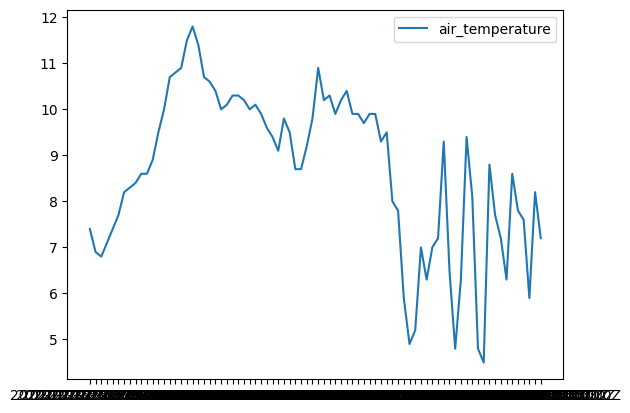

In [14]:
import matplotlib.pyplot as plt

fig, ax = plt.subplots()

x_axis = data["time"]
y_axis = data["air_temperature"]

ax.plot(x_axis, y_axis, label="air_temperature")
plt.legend()
plt.show()

### Værmelding oppgave 3

Som vi så i forrige oppgave ble x-aksen ikke særlig pen. 

Endre på tidspunkt-verdiene i `data['time']` slik at plottet ser litt bedre ut. Her står dere litt fritt. Lag et nytt plott og sjekk at det ble penere.

- Tips: Bruk `ax.set_xticks(dataDict['time'][::n])` for å endre hvor mange punkter på x-aksen som blir med. `n` bestemmer intervallet.

Her er et eksempel på en mer oversiktlig x-akse:

<img src="bilder/yr3.png" style="width: 700px;">

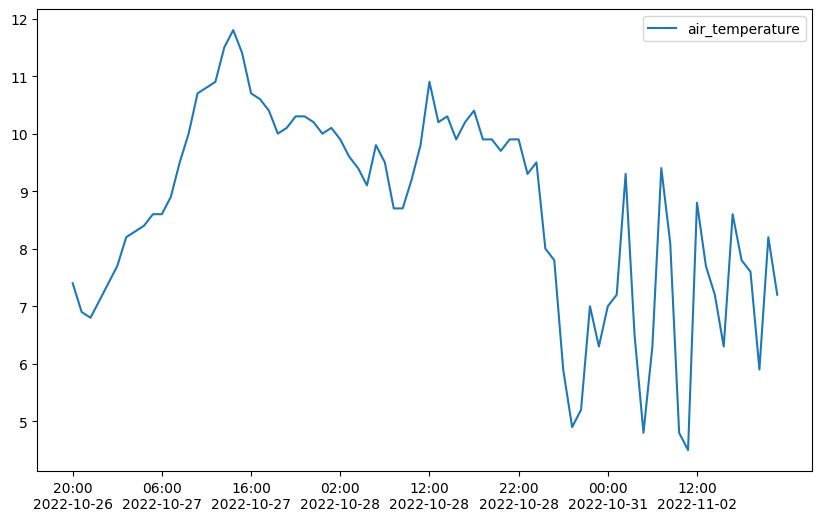

In [15]:
def format_date(datestr):
    date, time = datestr.split("T")
    hours, minutes, seconds = time.split(":")
    return f"{hours}:{minutes}\n{date}"

x_axis = []
for value in data["time"]:
    x_axis.append(format_date(value))

fig, ax = plt.subplots(figsize=(10, 6))
x_axis = np.array(x_axis)
y_axis = data["air_temperature"]

ax.plot(x_axis, y_axis, label="air_temperature")
ax.set_xticks(x_axis[::10])
plt.legend()
plt.show()

### Værmelding oppgave 4

For å gjøre jobben enklere for videre behandling av dataen, ønsker vi å lagre den på et annet format. 

Bruk `numpy.savetxt` for å lagre dataen fra `data`-dictionarien i nye tekstfiler. Lag en fil for hver nøkkel i dictionarien, men navn lik '{nøkkel}.txt' .

- Hint: bruk `fmt = '%.2f'` for tall, og `fmt = '%s'` for strenger


In [44]:
for column, values in data.items():
    if column == "time":
        format = "%s"
    else:
        format = "%.2f"    

    np.savetxt(f"{column}.txt", values, fmt=format)

Test at filene kan lastes inn igjen her:

In [45]:
air_temp = np.loadtxt("air_temperature.txt")
print(air_temp[:10])  # [ 7.4  6.9  6.8  7.1  7.4  7.7  8.2  8.3  8.4  8.6  ]

# Les in flere filer selv:

[7.4 6.9 6.8 7.1 7.4 7.7 8.2 8.3 8.4 8.6]


### Eksempel på bruk av subplots til å lage figurer med flere plots

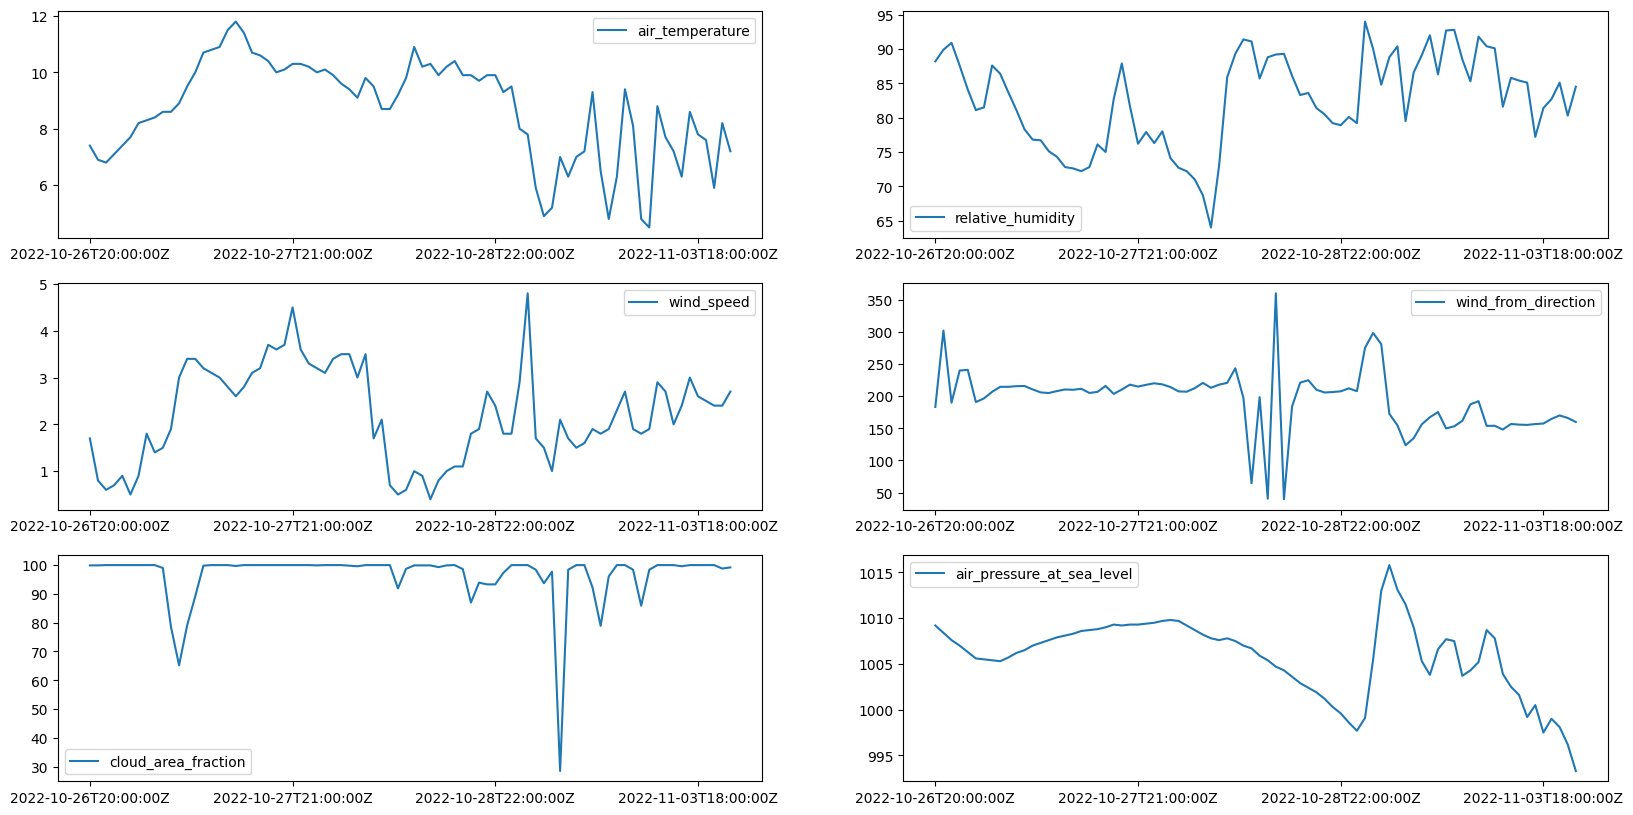

In [23]:
fig, axs = plt.subplots(3, 2, figsize=(20, 10))

axs[0, 0].plot(data["time"], data["air_temperature"], label="air_temperature")
axs[0, 1].plot(data["time"], data["relative_humidity"], label="relative_humidity")
axs[1, 0].plot(data["time"], data["wind_speed"], label="wind_speed")
axs[1, 1].plot(data["time"], data["wind_from_direction"], label="wind_from_direction")
axs[2, 0].plot(data["time"], data["cloud_area_fraction"], label="cloud_area_fraction")
axs[2, 1].plot(data["time"], data["air_pressure_at_sea_level"], label="air_pressure_at_sea_level")


for ax in axs.flatten():
    ax.set_xticks(data["time"][::25])
    ax.legend()

plt.show()

# Eksamensoppgaver

## Høst 2016
### Oppgave 4a

![Oppgave 4a, del 1](bilder/eksamen3.PNG)
![Oppgave 4a, del 2](bilder/eksamen4.PNG)

In [24]:
D = {
    1: "one",
    2: "two",
    3: "three",
    4: "four",
    5: "five",
    6: "six",
    7: "seven",
    8: "eight",
    9: "nine",
    10: "ten",
    11: "eleven",
    12: "twelve",
    13: "thirteen",
    14: "fourteen",
    15: "fifteen",
    16: "sixteen",
    17: "seventeen",
    18: "eighteen",
    19: "nineteen",
    20: "twenty",
    30: "thirty",
    40: "forty",
    50: "fifty",
    60: "sixty",
    70: "seventy",
    80: "eighty",
    90: "ninety",
}
L = [1000000, " million", 1000, " thousand", 1, ""]

In [25]:
def i2_txt(num):
    if num in D:
        return D[num]
    
    ones = num % 10
    tens = num - ones

    one_name = D[ones]
    ten_name = D[tens]
    
    return f"{ten_name}-{one_name}"

In [26]:
# test koden din her
print(i2_txt(71))
print(i2_txt(75))
print(i2_txt(44))
print(i2_txt(32))
print(i2_txt(1))
print(i2_txt(15))
print(i2_txt(98))

seventy-one
seventy-five
forty-four
thirty-two
one
fifteen
ninety-eight


#### Oppgave 4b
<img src="bilder/eksamen5.PNG" style="width: 700px">

In [27]:
def i3_txt(num):
    if num <= 99:
        return i2_txt(num)
    
    remainder = num % 100
    hundred_part = num // 100
    if remainder == 0:
        return D[hundred_part] + " hundred"
    
    return D[hundred_part] + " hundred " + i2_txt(remainder)

In [28]:
i3_txt(971)  # test koden din her

'nine hundred seventy-one'

## Høst 2015 
### Oppgave 4c

Sensor retter eksamen og setter poeng på hver oppgave med en poengsum som går fra og med 0 til og med 10, der 0 er dårligst (0% score) mens 10 er best (100% score). 
Sensur av en eksamen består av en liste med ett tall for hver deloppgave, i samme rekkefølge som de kommer (dvs. 1,2a,2b, osv.) 

Lag funksjonen `compute_score` med inn-parameteren points som er en liste med poengsummer for deloppgavene, og konstanten WEIGHTS. Funksjonen skal regne ut en totalscore i prosent for en eksamen, basert på vektingen av oppgavene. Eksempel på kjøring av funksjonen og hva den returnerer: 

```python 
>>> compute_score([10,10,10,10,10,10,10,10,10,10,10,10,10,10,10,10],WEIGHTS) # 100.0 
>>> compute_score([10,0,0,0,10,10,10,10,0,0,0,0,0,0,0,0],WEIGHTS) # 45.0 
>>> compute_score([5,0,0,0,10,10,10,10,0,0,0,0,0,0,0,0],WEIGHTS) # 32.5 
>>> compute_score([4,4,4,4,4,4,4,4,4,4,4,4,4,4,4,4],WEIGHTS) # 40.0 
```

In [29]:
WEIGHTS = (25, 5, 5, 5, 5, 5, 5, 5, 5, 5, 5, 5, 5, 5, 5, 5)

In [30]:
def compute_score(points, weights):
  score = 0
  for i in range(len(points)):
    score += points[i] / 10 * weights[i] 
  return score

In [31]:
# Test koden din her
print(
    compute_score(
        [10, 10, 10, 10, 10, 10, 10, 10, 10, 10, 10, 10, 10, 10, 10, 10], WEIGHTS
    )
)  # 100

print(
    compute_score([10, 0, 0, 0, 10, 10, 10, 10, 0, 0, 0, 0, 0, 0, 0, 0], WEIGHTS)
)  # 45

print(
    compute_score([5, 0, 0, 0, 10, 10, 10, 10, 0, 0, 0, 0, 0, 0, 0, 0], WEIGHTS)
)  # 32.5

print(compute_score([4, 4, 4, 4, 4, 4, 4, 4, 4, 4, 4, 4, 4, 4, 4, 4], WEIGHTS))  # 40

100.0
45.0
32.5
40.0


### Oppgave 4e

<img src="bilder/15_4e.png" style="width: 700px">

In [22]:
def add_candidate(candidate_num, scores, weights):
  total_score = compute_score(scores, weights)

  for i in range(len(scores)):
    scores[i] = str(scores[i])
  scores = "\t".join(scores)
  
  with open("eksamen.txt", "a") as file:
    file.write(f"{candidate_num}\t{scores}\t{total_score:.1f}\n")

In [23]:
add_candidate(12392, [10, 0, 0, 0, 10, 10, 10, 10, 10, 0, 0, 0, 0, 0, 0, 0], WEIGHTS)
add_candidate(
    33322, [0, 10, 10, 10, 0, 0, 0, 0, 0, 10, 10, 10, 10, 10, 10, 10], WEIGHTS
)

In [24]:
with open("eksamen.txt", "r") as f:
    print(f.read())

12392	10	0	0	0	10	10	10	10	10	0	0	0	0	0	0	0	50.0
33322	0	10	10	10	0	0	0	0	0	10	10	10	10	10	10	10	50.0



### Oppgave 4f

<img src="bilder/15_4f.png" style="width: 700px">

In [25]:
def read_result_file(filename):
  result = []
  with open(filename, "r") as file:
    for line in file.readlines():
      line = line.strip().split()

      for i in range(len(line)-1):
        line[i] = int(line[i])

      line[-1] = float(line[-1])

      result.append(line)

  return result

In [26]:
table = read_result_file("eksamen.txt")
print(table)

[[12392, 10, 0, 0, 0, 10, 10, 10, 10, 10, 0, 0, 0, 0, 0, 0, 0, 50.0], [33322, 0, 10, 10, 10, 0, 0, 0, 0, 0, 10, 10, 10, 10, 10, 10, 10, 50.0]]
